In [1]:
#!pip install rvc3python --upgrade

In [2]:
from spatialmath.base import plotvol2, transl2, trot2, trplot2, plot_point

from funcionesAuxiliares import *

<hr style="height: 5px; background-color: blue; border: none;">


### transformacion2D
Realiza una transformación en 2D, componiendo una translación y una rotación

**PARÁMETROS:**
* t: la translación
* alpha: el ángulo de rotación (en radianes)

**DEVUELVE:**
La matriz que expresa la combinación translación - rotación en coordenadas homogéneas

**EJEMPLOS:**

In [3]:
T1 = transformacion2D()
T2 = transformacion2D(alpha= np.pi/3)
T3 = transformacion2D( t = (1,2))
T4 = transformacion2D(alpha= np.pi/3, t = (1,2))

print(' T1: transformacion2D() :\n',transformacion2D())
print('\n  T2: transformacion2D(alpha= np.pi/3) :\n', transformacion2D(alpha= np.pi/3))
print('\n  T3: transformacion2D( t = (1,2)) :\n',transformacion2D( t = (1,2)))
print('\n  T4: transformacion2D(alpha= np.pi/3, t = (1,2)) :\n',transformacion2D(alpha= np.pi/3, t = (1,2)))

 T1: transformacion2D() :
 [[ 1. -0.  0.]
 [ 0.  1.  0.]
 [ 0.  0.  1.]]

  T2: transformacion2D(alpha= np.pi/3) :
 [[ 0.5       -0.8660254  0.       ]
 [ 0.8660254  0.5        0.       ]
 [ 0.         0.         1.       ]]

  T3: transformacion2D( t = (1,2)) :
 [[ 1. -0.  1.]
 [ 0.  1.  2.]
 [ 0.  0.  1.]]

  T4: transformacion2D(alpha= np.pi/3, t = (1,2)) :
 [[ 0.5       -0.8660254  1.       ]
 [ 0.8660254  0.5        2.       ]
 [ 0.         0.         1.       ]]


<hr style="height: 5px; background-color: blue; border: none;">

### inversa2D()

Data una matriz T, que representa una transformación en SE(2), devuelve su inversa

**PARÁMETROS**

T: la matriz

**DEVUELVE** 

Su inversa

**EXCEPCIONES** 

Si T no es una transformación válida en SE(2), la función lanza una excepción

**Ejemplos** 

In [4]:
print ('inversa2D(T1), T1 @ inversa2D(T1)\n', inversa2D(T1),'\n', T1 @ inversa2D(T1))
print ('\ninversa2D(T2), T2 @ inversa2D(T2)\n', inversa2D(T2),'\n', T2 @ inversa2D(T2))
print ('\ninversa2D(T3), T3 @ inversa2D(T3)\n', inversa2D(T3), '\n',T3 @ inversa2D(T3))
print ('\ninversa2D(T4), T4 @ inversa2D(T4)\n', inversa2D(T4), '\n',T4 @ inversa2D(T4))

inversa2D(T1), T1 @ inversa2D(T1)
 [[ 1.  0. -0.]
 [-0.  1. -0.]
 [ 0.  0.  1.]] 
 [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]

inversa2D(T2), T2 @ inversa2D(T2)
 [[ 0.5        0.8660254 -0.       ]
 [-0.8660254  0.5       -0.       ]
 [ 0.         0.         1.       ]] 
 [[1.00000000e+00 1.48741681e-17 0.00000000e+00]
 [1.48741681e-17 1.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]

inversa2D(T3), T3 @ inversa2D(T3)
 [[ 1.  0. -1.]
 [-0.  1. -2.]
 [ 0.  0.  1.]] 
 [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]

inversa2D(T4), T4 @ inversa2D(T4)
 [[ 0.5         0.8660254  -2.23205081]
 [-0.8660254   0.5        -0.1339746 ]
 [ 0.          0.          1.        ]] 
 [[1.00000000e+00 1.48741681e-17 1.11022302e-16]
 [1.48741681e-17 1.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]


<hr style="height: 5px; background-color: blue; border: none;">

### angulo

Dado un vector  $\vec{v} $, 
devuelve su ángulo de dirección: el ángulo $\theta$ tal que 
$\vec{v} \ = \ v \left( \cos \theta, \sin \theta \right)$.
$\theta$ viene expresado en radianes.

**PARÁMETROS**

v, una tupla, lista o np.array de dos componentes

**DEVUELVE**

su ángulo director

**EXCEPCIONES**

Si v=(0,0), su ángulo de dirección no está definido: la función lanza una excepción

**Ejemplos**

In [5]:
print ('angulo (3,-2):',angulo ( (3,-2) ) )
print ('angulo (3,0):',angulo ( (3,0) ) )
print ('angulo (-3,0):',angulo ( (-3,0) ) )
print ('angulo (0,3):',angulo ( (0,3) ) )
print ('angulo (0,-3):',angulo ( (0,-3) ) )

   
try:
   print ('angulo (0,0):',angulo ( (0,0) ) )
except ValueError as error:
    print(error)

angulo (3,-2): -0.5880026035475675
angulo (3,0): 0.0
angulo (-3,0): 3.141592653589793
angulo (0,3): 1.5707963267948966
angulo (0,-3): -1.5707963267948966
El ángulo del vector (0,0) no está definido


<hr style="height: 5px; background-color: blue; border: none;">

### muestraDesplazamiento

Dadas dos transformaciones, T0 y T1, muestra en pantalla la evolución del twist que transforma T0 en T1.

En particular: suponemos un marco que en un instante t=0 coincide con T0 y en t=1 con T0@T1.

La función genera un *twist* Twist(una transformación continua con velocidades lineal y angular constantes)

tal que Twist(0) = $I$ (transformación neutra) y Twist (1) = T0@T1,

y muestra gráficamente el marco a intervalos regulares de tiempo iguales a $\Delta t = \frac{1}{nIntervalos}$:

T0@Twist (0) = T0, T0@Twist ($\Delta t$), T0@Twist ($2 * \Delta t$), T0@Twist ($3 * \Delta t$), ... T0@T1

**PARÁMETROS**
* T0 (np.array 3x3): Transformación inicial. Debe ser una matriz válida en SE(2)
* T  (np.array 3x3): Transformación que se expresa como un twist. Debe ser una matriz válida en SE(2)
* nIntervalos (int): El número de transformaciones intermedias entre T0 y T0@T (valor por defecto: 10)
* originsize (integer): Tamaño con que se muestra el origen de los marcos de referencia (valor por defecto, 0)
* origincolor (string): Color con que se muestran los orígenes de los marcos de referencia (valor por defecto,'red')

**EXCEPCIONES**

La función lanza excepciones en los siguientes casos si T0 o T no son transformaciones válidas en SE(2).

Si *nIntervalos* es menor que 1, se le reasigna el valor 10


**Ejemplo**

<Axes: xlabel='X', ylabel='Y'>

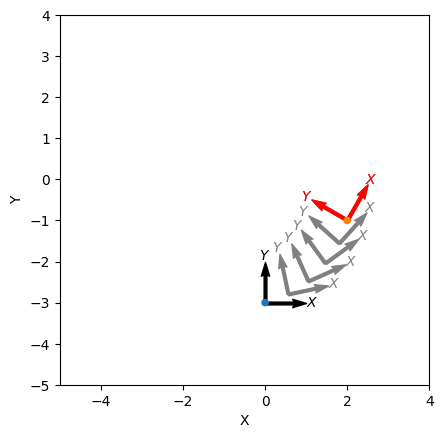

In [6]:
T0 = transl2(0,-3)
T = transl2(2,2) @ trot2 (np.pi/3)
ejes=plotvol2([-5,4])
muestraDesplazamiento (T0, T, nIntervalos = 5)
trplot2(T0, color='black')
trplot2(T0@T, color='red')

<hr style="height: 5px; background-color: blue; border: none;">

### transfCoord 
Dadas las coordenadas euclídeas de un punto en un marco $A$, $^A\mathbf{x}$, y la transformación $^AT_B \in SE(2)$, que transforma el marco $A$ en el $B$,
devuelve las coordenadas del punto en el marco $B$: 
$^B\mathbf{x} = \left(  ^AT_B \right)^{-1}$ $^A\mathbf{x}$

**PARÁMETROS**
- T: $^AT_B$: Una transformación en SE(2).
- coord:  $^A\mathbf{x}$ (np.array de 2 componentes): Las coordenadas euclídeas de un punto en el marco $A$.


**DEVUELVE**

$^B\mathbf{x}$ (np.array de 2 componentes): las coordenadas euclídeas del punto en el marco $B = A \ ^AT_B$.
 
**EXCEPCIONES**

Si $^AT_B$ no es una transformación válida en SE(2), lanza una excepción

**Ejemplos**

In [7]:
P = (2,3)
print (transfCoord (transl2(1,1),P).reshape(2,))

P = (2,0)
print (transfCoord (trot2(np.pi/4),P).reshape(2,))

[1. 2.]
[ 1.41421356 -1.41421356]


<hr style="height: 5px; background-color: blue; border: none;">


### perpendicular

**PARÁMETROS**
* v (tupla, lista o np.array de dos componentes): un vector en $\mathbb{R}^2$

**DEVUELVE**
* Un vector unitario (con norma = 1) perpendicular a v.

**EXCEPCIONES**  
La función lanza excepciones:
* Si v no es un tipo válido (tupla, lista o np.array) 
* Si v = (0,0)

**Ejemplos**

In [8]:
try:
    print('Un vector perpendicular a (1,0) es ', perpendicular ( (1,0)))
    print('Un vector perpendicular a (3,4) es ', perpendicular ( (3,4)))
    print('Un vector perpendicular a (0,0) es ', perpendicular ( (0,0)))
except ValueError as error:
    print(error)

Un vector perpendicular a (1,0) es  [0. 1.]
Un vector perpendicular a (3,4) es  [-0.8  0.6]
No está definido el vector perpendicular a (0,0) 


<hr style="height: 5px; background-color: blue; border: none;">


### inicializa

Genera los puntos iniciales, P1 y P2, así como el marco inicial.
El centro de P1, P2 es el origen de coordenadas, y |P1-P2| = 1.
El origen del marco inicial está a una distancia respecto del origen de coordenadas menor o igual a L.

**PARÁMETROS**
* L (float): distancia máxima entre el origen de coordenadas y el de T0.

**DEVUELVE**
Dos puntos, P1 y P2, y el marco inicial.

**EXCEPCIONES**  
Si L no es positivo, toma por defecto L=5

**Ejemplos**

[[<matplotlib.lines.Line2D at 0x16ab7d49430>]]

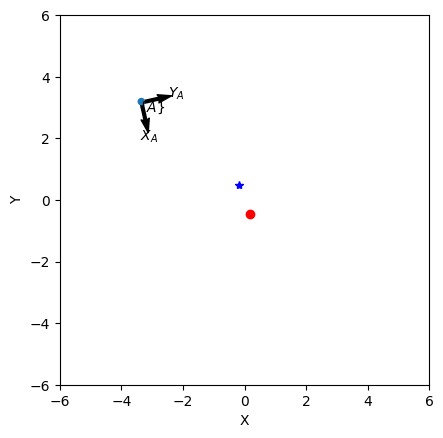

In [9]:
L = 5
P1, P2, T0 = inicializa(L=L)
plotvol2 ([-L-1,L+1])
trplot2 (T0, color='black',frame='A')
plot_point (P1, marker='o', color='red',label='A')
plot_point (P2, marker='*', color='blue')

<hr style="height: 5px; background-color: blue; border: none;">

### muestraMovimiento

Representa gráficamente la evolución de un marco inicial que sufre una serie de transformaciones.
En el caso de transformaciones que no sean translaciones ni rotaciones puras, muestra la evolución de su twist asociado.

**PARÁMETROS**
* listaTransf: tupla o lista de transformaciones
* colores (tupla o lista de strings): colores con que identifican las sucesivas transformaciones, por defecto: ('black', 'blue', 'orange','red', 'green')


**EXCEPCIONES**

Si alguna de las matrices de listaTransf no es una transformación válida en SE(2), lanza una excepción

**Ejemplos**

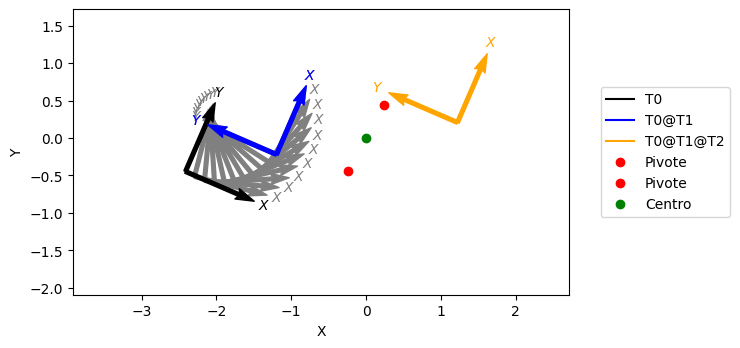

In [10]:
P1, P2, T0 = inicializa()
centro = (P1+P2)/2

centro = transfCoord(T0, centro)
T1 = transl2 (centro/2) @ trot2 (np.pi/2)

centro = transfCoord(T1, centro)
T2 = transl2 (2*centro)
muestraMovimiento ( (T0, T1, T2))

for p in (P1, P2):
    plot_point (p, marker='o', color='red', label='Pivote')
plot_point ( (P1+P2)/2, marker ='o', color='green', label = 'Centro')
plt.legend(loc='center left', bbox_to_anchor=(1.05, 0.5))